In [1]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

In [3]:
conn = sql.connect("chinook.db")
conn

In [4]:
"select* from sqlite_master"

'select* from sqlite_master'

In [6]:
pd.read_sql_query("select* from sqlite_master", conn)

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


In [7]:
def sql_query(q):
    return pd.read_sql_query(q,conn)

## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

In [8]:
Top_10_Genre = """
SELECT 
    g.name AS genre,
    COUNT(t.track_id) AS track_count
FROM genre AS g
JOIN track AS t
    ON g.genre_id = t.genre_id
GROUP BY g.genre_id, g.name
ORDER BY track_count DESC
LIMIT 10;
"""

Top_10_Genre = pd.read_sql_query(Top_10_Genre, conn)
Top_10_Genre

,genre,track_count
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


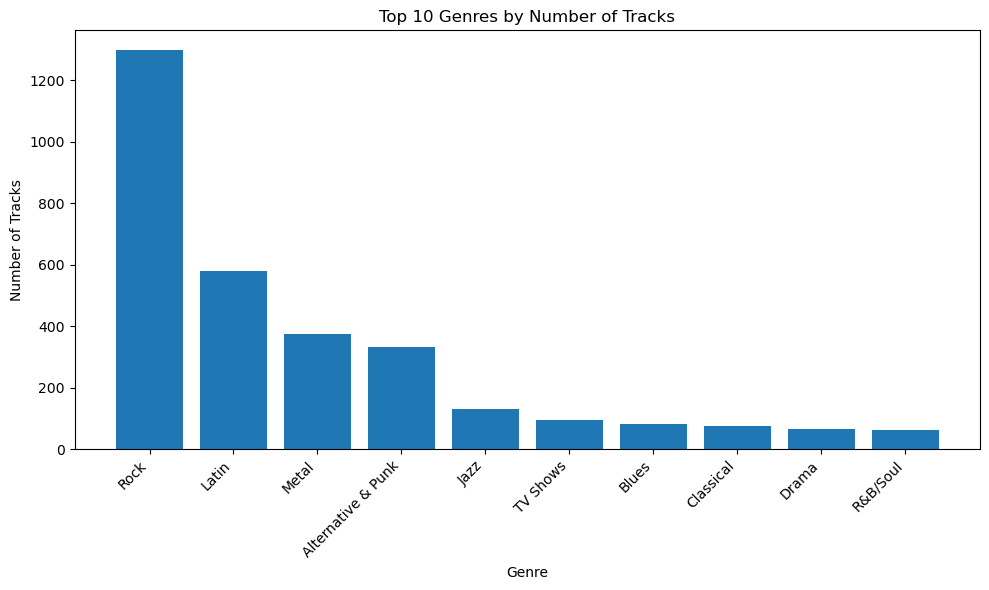

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(Top_10_Genre["genre"], Top_10_Genre["track_count"])

plt.title("Top 10 Genres by Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [11]:
query = """
SELECT 
    a.title AS album,
    COUNT(t.track_id) AS track_count
FROM album AS a
JOIN track AS t
    ON a.album_id = t.album_id
GROUP BY a.album_id, a.title
ORDER BY track_count DESC
LIMIT 10;
"""

Top_10_Albums = pd.read_sql_query(query, conn)
Top_10_Albums

,album,track_count
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"Lost, Season 1",25
5,"The Office, Season 3",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Afrociberdelia,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [12]:
query3 = """
SELECT 
    c.customer_id,
    c.first_name || ' ' || c.last_name AS customer,
    ROUND(SUM(i.total), 2) AS total_spent
FROM customer AS c
JOIN invoice AS i
    ON c.customer_id = i.customer_id
GROUP BY 
    c.customer_id,
    c.first_name,
    c.last_name
ORDER BY total_spent DESC
LIMIT 10;
"""

Top_10_Customer = pd.read_sql_query(query3, conn)
Top_10_Customer

,customer_id,customer,total_spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [13]:
query= """
SELECT 
    ar.artist_id,
    ar.name AS artist,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
JOIN invoice_line AS il
    ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY revenue DESC
LIMIT 5;
"""
Top_5_Artists = pd.read_sql_query(query, conn)
Top_5_Artists

,artist_id,artist,revenue
0,51,Queen,190.08
1,94,Jimi Hendrix,185.13
2,110,Nirvana,128.70
3,127,Red Hot Chili Peppers,128.70
4,118,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [15]:
query = """
SELECT 
    billing_country AS country,
    ROUND(AVG(total), 2) AS avg_revenue_per_invoice
FROM invoice
GROUP BY billing_country
ORDER BY avg_revenue_per_invoice DESC;
"""
Average = pd.read_sql_query(query, conn)
Average

,country,avg_revenue_per_invoice
0,Czech Republic,9.11
1,Spain,8.91
2,Ireland,8.83
3,United Kingdom,8.77
4,India,8.72
5,Belgium,8.63
6,Germany,8.16
7,Australia,8.12
8,Norway,8.03
9,USA,7.94


## Q6. Write a query to find the media type with number of tracks.


In [16]:
query = """
SELECT
    mt.name AS media_type,
    COUNT(t.track_id) AS track_count
FROM media_type AS mt
JOIN track AS t
    ON mt.media_type_id = t.media_type_id
GROUP BY mt.media_type_id, mt.name
ORDER BY track_count DESC;
"""

Media_Type = pd.read_sql_query(query, conn)
Media_Type

,media_type,track_count
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [17]:
query= """
SELECT
    ar.name AS artist,
    COUNT(DISTINCT g.genre_id) AS genre_count
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
JOIN genre AS g
    ON t.genre_id = g.genre_id
GROUP BY ar.artist_id, ar.name
HAVING COUNT(DISTINCT g.genre_id) > 1
ORDER BY genre_count DESC, artist;
"""

Artists = pd.read_sql_query(query, conn)
Artists

,artist,genre_count
0,Iron Maiden,4
1,Audioslave,3
2,Battlestar Galactica,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Various Artists,3
7,Amy Winehouse,2
8,Antônio Carlos Jobim,2
9,Eric Clapton,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [18]:
query = """
SELECT
    track_id,
    name AS track,
    ROUND(milliseconds / 60000.0, 2) AS duration_minutes
FROM track
ORDER BY milliseconds DESC
LIMIT 10;
"""

Top_10_Longest_Tracks = pd.read_sql_query(query, conn)
Top_10_Longest_Tracks

,track_id,track,duration_minutes
0,2820,Occupation / Precipice,88.12
1,3224,Through a Looking Glass,84.81
2,3244,"Greetings from Earth, Pt. 1",49.34
3,3242,The Man With Nine Lives,49.28
4,3227,"Battlestar Galactica, Pt. 2",49.27
5,3226,"Battlestar Galactica, Pt. 1",49.21
6,3243,Murder On the Rising Star,48.93
7,3228,"Battlestar Galactica, Pt. 3",48.80
8,3248,Take the Celestra,48.79
9,3239,Fire In Space,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

In [19]:
query= """
SELECT
    ar.name AS artist,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
JOIN invoice_line AS il
    ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY revenue DESC;
"""

artist_revenue = pd.read_sql_query(query, conn)

total_revenue = artist_revenue["revenue"].sum()

top5 = artist_revenue.head(5).copy()

top5["revenue_percentage"] = (
    top5["revenue"] / total_revenue
) * 100

top5

,artist,revenue,revenue_percentage
0,Queen,190.08,4.036157
1,Jimi Hendrix,185.13,3.931049
2,Nirvana,128.70,2.732815
3,Red Hot Chili Peppers,128.70,2.732815
4,Pearl Jam,127.71,2.711793


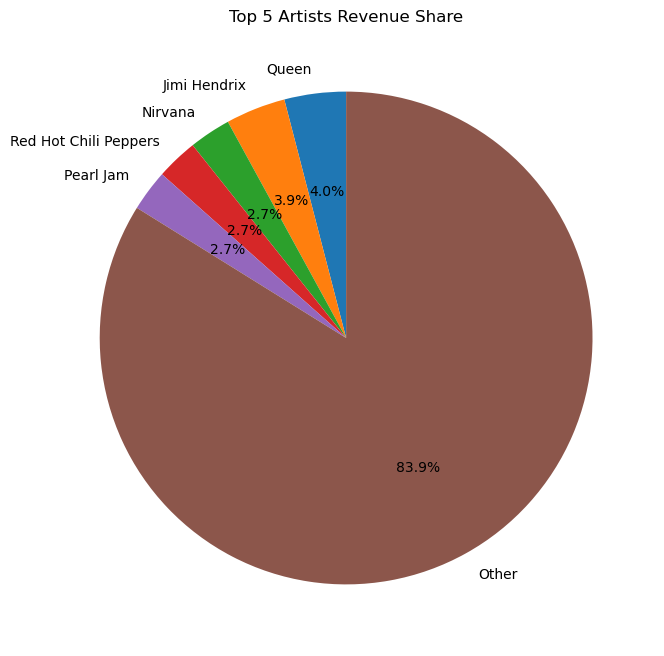

In [20]:
other_revenue = total_revenue - top5["revenue"].sum()

pie_labels = list(top5["artist"]) + ["Other"]

pie_values = list(top5["revenue"]) + [other_revenue]

plt.figure(figsize=(8, 8))

plt.pie(
    pie_values,
    labels=pie_labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Artists Revenue Share")

plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

In [21]:
query = """
SELECT
    i.billing_country AS country,
    g.name AS genre,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice AS i
JOIN invoice_line AS il
    ON i.invoice_id = il.invoice_id
JOIN track AS t
    ON il.track_id = t.track_id
JOIN genre AS g
    ON t.genre_id = g.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.billing_country, g.name
ORDER BY i.billing_country, revenue DESC;
"""

Genre = pd.read_sql_query(query, conn)
Genre

,country,genre,revenue
0,Argentina,Rock,10.89
1,Argentina,Metal,1.98
2,Argentina,Latin,1.98
3,Australia,Rock,33.66
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Latin,21.78
67,United Kingdom,Rock,164.34
68,United Kingdom,Metal,30.69
